# Thu thập và khám phá dữ liệu TMDB + IMDb

**Bản làm việc ngày 15/11/2026.** Đầu vào là CSV nhóm tải ngày 05/11/2026.
Mục tiêu: kiểm tra cấu trúc, chất lượng và các mẫu hình sơ bộ trước khi chốt câu hỏi.
Các thống kê raw đếm **bản ghi**, chưa mặc định mỗi dòng là một phim duy nhất.

Chọn kernel **Python (movies-dataset)** rồi **Restart Kernel and Run All Cells**.
Notebook chạy từ thư mục gốc hoặc `notebooks/`, không tải dữ liệu khi chạy và không ghi đè CSV.
Các phép chuyển kiểu, tách thể loại và lọc mẫu chỉ phục vụ kiểm tra trong bộ nhớ.

Codex hỗ trợ mã kiểm tra và ghi chú kỹ thuật; xem [nhật ký LLM](../LLM_USAGE.md).
Theo mục 6 của [đề bài](../doc/CSC17104_2026_Final_Project.pdf), nhóm cần hiểu từng dòng mã,
tự viết phần phân tích, câu trả lời và reflection cho bài nộp.

## 1. Nguồn và bối cảnh

- **Chủ đề.** Bộ dữ liệu mô tả các tác phẩm trong danh mục phim TMDB được liên kết với bản ghi IMDb.
  Dữ liệu bao gồm đặc điểm tác phẩm như thể loại, ngôn ngữ, thời lượng và ngày phát hành, cùng ngân sách, doanh thu,
  điểm đánh giá và số lượt chấm. Nhóm dùng dữ liệu để tìm hiểu mối liên hệ giữa đặc điểm phim, kết quả tài chính
  và đánh giá của khán giả trên hai nền tảng.
- **Nguồn gốc.** Nhóm sử dụng file CSV trong bộ [TMDB + IMDB Merged Movies Dataset](https://www.kaggle.com/datasets/ggtejas/tmdb-imdb-merged-movies-dataset/data)
  do **Tejas Garg (`ggtejas`)** công bố trên Kaggle. Trong phần mô tả, tác giả dẫn hai nguồn dữ liệu.

  - **TMDB.** Tác giả lấy thông tin phim như tên, ngày phát hành và doanh thu từ [bộ dữ liệu TMDB do `asaniczka` đăng trên Kaggle](https://www.kaggle.com/datasets/asaniczka/tmdb-movies-dataset-2023-930k-movies).
  - **IMDb.** Tác giả sử dụng [IMDb Non-Commercial Datasets](https://developer.imdb.com/non-commercial-datasets/)
    do IMDb cung cấp để bổ sung thông tin như đạo diễn, biên kịch, diễn viên, điểm và số lượt chấm trên IMDb.

  Phiên bản đầu tiên trên Kaggle (**v1**) ghi ngày **13/11/2024**. Nhóm tải bản **v578** ngày **05/11/2026**,
  cùng ngày bản này được cập nhật trên Kaggle. SHA-256 của CSV nhóm dùng khớp với CSV tải lại từ v578.
- **Giấy phép:** [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/) của bản tổng hợp;
  ghi nguồn và các thay đổi, sử dụng phi thương mại, tuân thủ điều kiện chia sẻ tương tự.
  Đối chiếu thêm điều kiện của [IMDb](https://developer.imdb.com/non-commercial-datasets/)
  và [TMDB](https://developer.themoviedb.org/docs/faq); nhãn của bản tổng hợp không thay thế điều kiện nguồn.
- **Cách thu thập dữ liệu (Collection method).** Nhóm tải CSV đã được tác giả tổng hợp từ hai nguồn có sẵn.
  Tác giả chưa mô tả chi tiết quy tắc ghép bản ghi hay cách xử lý mã trùng.

  - **Phạm vi tác phẩm.** Dữ liệu bao gồm các bản ghi tác phẩm có trong bản ghép v578. Mức độ bao phủ toàn bộ
    danh mục TMDB và IMDb chưa được xác nhận. CSV thiếu trường `titleType` để phân biệt chắc chắn phim điện ảnh,
    phim ngắn và tác phẩm truyền hình.
  - **Thời kỳ dữ liệu.** Trong CSV, ngày phát hành ghi nhận nằm từ **09/12/1874** đến **13/10/2029**.
    Khoảng này có cả ngày sau ngày nhóm tải. Tác giả chưa công bố thời điểm trích xuất từng nguồn,
    nên thời điểm ghi nhận điểm và lượt chấm của mỗi nền tảng chưa được xác minh.
  - **Giới hạn và khả năng sai lệch.** Các bản ghi trong CSV có thể thiên về những tác phẩm có thông tin ở cả hai
    nền tảng. CSV thiếu đơn vị tiền tệ theo từng dòng và chưa có xác nhận về cách chuẩn hóa hay điều chỉnh lạm phát.
    Để tính lợi nhuận thực còn cần các khoản chi phí và khoản phân chia doanh thu ngoài những gì CSV ghi nhận.
- **Lý do chọn:** Chủ đề phim ảnh gần gũi. Dữ liệu có thông tin tài chính, thuộc tính đa nhãn và điểm từ hai nền tảng,
  phù hợp tìm hiểu các khác biệt theo nhóm và theo thời gian.

Tài liệu IMDb định nghĩa `averageRating` là điểm trung bình có trọng số và `numVotes` là số lượt chấm;
`tconst` là mã tác phẩm. Metadata nguồn là mô tả của người công bố, không chứng minh chất lượng từng bản ghi.

In [1]:
from pathlib import Path
import csv
import hashlib
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'environment.yml').is_file() and (p / 'data/raw').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook từ thư mục repository hoặc notebooks/.')
RAW_PATH = ROOT / 'data/raw/TMDB  IMDB Movies Dataset.csv'
if not RAW_PATH.is_file():
    raise FileNotFoundError(f'Tải CSV theo README và đặt tại: {RAW_PATH}')
DOWNLOAD_DATE = pd.Timestamp('2026-11-05')
RANDOM_STATE = 42
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_columns', 12)
sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 11, 'axes.labelsize': 10})
display(pd.Series({'Python': platform.python_version(), 'pandas': pd.__version__,
                   'numpy': np.__version__, 'matplotlib': matplotlib.__version__,
                   'seaborn': sns.__version__, 'executable': sys.executable}, name='Môi trường'))

def file_sha256(path):
    h = hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

raw_sha256 = file_sha256(RAW_PATH)
print('SHA-256:', raw_sha256)
# Giữ nguyên chuỗi như NA/N/A/NULL nếu có; chỉ ô trống và ký hiệu IMDb \N là thiếu.
movies = pd.read_csv(RAW_PATH, low_memory=False, keep_default_na=False, na_values=['', r'\N'])
n = len(movies)
display(pd.Series({'dòng': n, 'cột': movies.shape[1], 'byte': RAW_PATH.stat().st_size,
                   'SHA-256': raw_sha256, 'ngày tải': str(DOWNLOAD_DATE.date())}, name='CSV cục bộ'))
display(movies[['id', 'tconst', 'title', 'release_date', 'budget', 'revenue']].head())

Python                                                   3.13.9
pandas                                                    2.3.3
numpy                                                     2.2.1
matplotlib                                               3.10.8
seaborn                                                  0.13.2
executable    C:\Users\KhangTran\AppData\Local\Programs\Pyth...
Name: Môi trường, dtype: object

SHA-256: f1c78500acd6a953492bdaa2413015b54baa082a213628e8ecd96be4e5dfe5f4


dòng                                                               443656
cột                                                                    29
byte                                                            282010663
SHA-256                 f1c78500acd6a953492bdaa2413015b54baa082a213628...
ngày tải                                                       2026-11-05
Name: CSV cục bộ, dtype: object

,id,tconst,title,release_date,budget,revenue
0,27205,tt1375666,Inception,2010-07-15,160000000,825532764
1,157336,tt0816692,Interstellar,2014-11-05,165000000,701729206
2,155,tt0468569,The Dark Knight,2008-07-16,185000000,1004558444
3,19995,tt0499549,Avatar,2009-12-15,237000000,2923706026
4,24428,tt0848228,The Avengers,2012-04-25,220000000,1518815515


## 2. Cấu trúc, dòng rỗng và định danh

Đếm bản ghi bằng bộ đọc CSV để không nhầm xuống dòng trong văn bản có dấu nháy với bản ghi mới.
`dòng dư` là số lần xuất hiện sau lần đầu (`duplicated()`);
`dòng liên quan` gồm tất cả dòng thuộc nhóm lặp (`duplicated(keep=False)`).
Chuỗi chỉ chứa khoảng trắng được tính riêng, sau đó gộp vào mặt nạ thiếu để kiểm tra.

In [2]:
empty_records = 0
all_blank_records = 0
wrong_width_records = 0
csv_records = 0
with RAW_PATH.open(encoding='utf-8-sig', newline='') as f:
    reader = csv.reader(f)
    header = next(reader)
    for row in reader:
        csv_records += 1
        if not row:
            empty_records += 1
        else:
            all_blank_records += all(not value.strip() for value in row)
            wrong_width_records += len(row) != len(header)

missing = movies.isna().copy()
space_only = pd.Series(0, index=movies.columns, dtype='int64')
for col in movies.select_dtypes(include=['object', 'string']):
    blank = movies[col].str.fullmatch(r'\s+', na=False)
    space_only[col] = blank.sum()
    missing[col] |= blank

structure = pd.Series({
    'bản ghi CSV kể cả bản ghi rỗng': csv_records,
    'bản ghi rỗng không trường': empty_records,
    'bản ghi mọi trường trống/khoảng trắng': all_blank_records,
    'bản ghi không rỗng sai số trường': wrong_width_records,
    'dòng mọi cột thiếu sau đọc': int(missing.all(axis=1).sum()),
    'dòng trùng toàn bộ (dư)': int(movies.duplicated().sum()),
})
display(structure.to_frame('Số lượng'))
key_rows = []
for col in ['id', 'tconst']:
    known = movies.loc[~missing[col], col]
    key_rows.append([col, missing[col].sum(), known.nunique(), known.duplicated().sum(),
                     known.duplicated(keep=False).sum()])
key_audit = pd.DataFrame(key_rows, columns=['khóa', 'thiếu', 'giá trị khác nhau', 'dòng dư', 'dòng liên quan'])
display(key_audit)
id_to_imdb = movies.groupby('id')['tconst'].nunique()
imdb_to_id = movies.groupby('tconst')['id'].nunique()
display(pd.Series({'id có nhiều tconst': int(id_to_imdb.gt(1).sum()),
                   'tconst có nhiều id': int(imdb_to_id.gt(1).sum()),
                   'id không dương': int(movies.id.le(0).sum()),
                   'tconst sai mẫu tt + chữ số': int((~movies.tconst.str.fullmatch(r'tt\d+', na=False)).sum())}))
dup_id_rows = movies.loc[movies.id.duplicated(keep=False)]
conflict_counts = dup_id_rows.groupby('id').nunique(dropna=False).gt(1).sum().sort_values(ascending=False)
display(conflict_counts.to_frame('Số nhóm id có nhiều giá trị kể cả thiếu'))
display(movies.groupby('tconst').agg(so_dong=('id', 'size'), so_id=('id', 'nunique'))
        .sort_values('so_dong', ascending=False).head(10))
unique_keys = (~movies.id.duplicated(keep=False) & ~movies.tconst.duplicated(keep=False)
               & ~missing.id & ~missing.tconst)
display(Markdown(f'Có **{movies.id.nunique():,} id TMDB** và **{movies.tconst.nunique():,} tconst IMDb** '
                 f'trong **{n:,} bản ghi**. Không thể coi từng dòng là một phim độc lập. '
                 f'Mẫu có cả hai mã xuất hiện đúng một lần gồm **{unique_keys.sum():,} dòng** '
                 f'({unique_keys.mean():.2%} raw); người dùng đã chọn mẫu A này cho phần quan hệ.'))

,Số lượng
bản ghi CSV kể cả bản ghi rỗng,443656
bản ghi rỗng không trường,0
bản ghi mọi trường trống/khoảng trắng,0
bản ghi không rỗng sai số trường,0
dòng mọi cột thiếu sau đọc,0
dòng trùng toàn bộ (dư),0


,khóa,thiếu,giá trị khác nhau,dòng dư,dòng liên quan
0,id,0,429762,13894,17372
1,tconst,0,426661,16995,18467


id có nhiều tconst               0
tconst có nhiều id            1424
id không dương                   0
tconst sai mẫu tt + chữ số       0
dtype: int64

,Số nhóm id có nhiều giá trị kể cả thiếu
cast,3429
popularity,51
release_date,39
genres,37
poster_path,35
production_companies,22
production_countries,20
spoken_languages,20
runtime,14
original_language,9


,so_dong,so_id
tconst,,
tt32094375,3996,148
tt26900526,1892,86
tt1757779,810,45
tt13904644,702,54
tt22075376,406,29
tt29703523,261,29
tt0813980,247,19
tt5719786,238,34
tt2705436,193,17


Có **429,762 id TMDB** và **426,661 tconst IMDb** trong **443,656 bản ghi**. Không thể coi từng dòng là một phim độc lập. Mẫu có cả hai mã xuất hiện đúng một lần gồm **425,189 dòng** (95.84% raw); người dùng đã chọn mẫu A này cho phần quan hệ.

### Ý nghĩa và hướng sử dụng 29 cột

Kiểu dưới đây là kiểu pandas đọc được; ý nghĩa lấy từ README và tài liệu nguồn ở mục 1.
Các hướng xử lý chỉ là đề xuất cho bước phân tích. Chưa bỏ cột hoặc thay thế giá trị trong `movies`.

In [3]:
column_notes = {
    'id': ('Mã tác phẩm TMDB', 'Giữ làm khóa, kiểm tra lặp; không dùng như đại lượng số'),
    'title': ('Tên tác phẩm', 'Giữ để kiểm tra ví dụ, không dùng tên làm khóa'),
    'vote_average': ('Điểm TMDB trên thang 0–10', 'Xét cùng vote_count; đánh dấu điểm 0 cần kiểm tra'),
    'vote_count': ('Số lượt chấm TMDB', 'Giữ số nguyên không âm; kiểm tra các ngưỡng lượt chấm'),
    'status': ('Trạng thái sản xuất/phát hành', 'Có thể chuyển category; giữ để phân tầng'),
    'release_date': ('Ngày phát hành được ghi nhận', 'Tạo datetime với lỗi thành NaT; tách năm/thập niên'),
    'revenue': ('Doanh thu được ghi nhận; đơn vị từng dòng chưa xác minh', 'Đếm riêng 0; không suy ra doanh thu thực bằng 0'),
    'runtime': ('Thời lượng theo phút', 'Kiểm tra 0 và cực trị, không tự cắt ngưỡng'),
    'adult': ('Cờ nội dung người lớn TMDB', 'Giữ boolean, có thể phân tầng; không tự loại'),
    'backdrop_path': ('Đường dẫn ảnh nền', 'Bỏ khỏi ma trận phân tích số nếu không dùng ảnh'),
    'budget': ('Ngân sách được ghi nhận; đơn vị từng dòng chưa xác minh', 'Đếm riêng 0; không tự điền bằng trung bình'),
    'homepage': ('Trang web của tác phẩm', 'Bỏ khỏi mô hình nếu không dùng; kiểm tra ô khoảng trắng'),
    'tconst': ('Mã tác phẩm IMDb', 'Giữ chuỗi, kiểm tra lặp và quan hệ với id'),
    'original_language': ('Mã ngôn ngữ gốc', 'Kiểm tra nhãn/nhóm hiếm trước khi chuyển category'),
    'original_title': ('Tên nguyên gốc', 'Giữ để đối chiếu; không suy ra khóa duy nhất'),
    'overview': ('Tóm tắt nội dung', 'Có thể bỏ ở phân tích dạng bảng; không tự điền văn bản'),
    'popularity': ('Chỉ số phổ biến TMDB tại thời điểm nguồn', 'Giữ số; không coi là doanh thu hay điểm đánh giá'),
    'poster_path': ('Đường dẫn poster', 'Bỏ khỏi ma trận phân tích số nếu không dùng ảnh'),
    'tagline': ('Câu giới thiệu', 'Có thể bỏ khi không làm NLP'),
    'genres': ('Các thể loại, nhiều nhãn trên một dòng', 'Tách dấu phẩy sau kiểm tra; tránh cộng trùng doanh thu'),
    'production_companies': ('Các công ty sản xuất', 'Đa nhãn; kiểm tra dấu phân cách trước khi tách'),
    'production_countries': ('Các quốc gia sản xuất', 'Đa nhãn; giữ thông tin thiếu'),
    'spoken_languages': ('Các ngôn ngữ được sử dụng', 'Đa nhãn, khác ngôn ngữ gốc'),
    'keywords': ('Từ khóa nội dung', 'Đa nhãn; có thể bỏ nếu ngoài hướng câu hỏi'),
    'directors': ('Tên đạo diễn', 'Có thể nhiều người; tên không bảo đảm định danh duy nhất'),
    'writers': ('Tên biên kịch', 'Có thể nhiều người; không tự gộp người trùng tên'),
    'averageRating': ('Điểm trung bình có trọng số IMDb, thang 1–10', 'Xét cùng numVotes'),
    'numVotes': ('Số lượt chấm IMDb', 'Giữ số nguyên không âm; không nhầm với vote_count'),
    'cast': ('Danh sách diễn viên', 'Kiểm tra khác biệt giữa các dòng cùng mã; chưa gộp tự động'),
}
assert set(column_notes) == set(movies.columns), 'Schema CSV đã thay đổi: cập nhật từ điển cột.'
schema = pd.DataFrame(column_notes, index=['ý nghĩa', 'hướng xử lý dự kiến']).T
schema.insert(0, 'dtype raw', movies.dtypes.astype(str))
schema.insert(1, 'số giá trị khác nhau', movies.nunique(dropna=True))
with pd.option_context('display.max_colwidth', None):
    display(schema)

,dtype raw,số giá trị khác nhau,ý nghĩa,hướng xử lý dự kiến
id,int64,429762,Mã tác phẩm TMDB,"Giữ làm khóa, kiểm tra lặp; không dùng như đại lượng số"
title,object,369958,Tên tác phẩm,"Giữ để kiểm tra ví dụ, không dùng tên làm khóa"
vote_average,float64,4996,Điểm TMDB trên thang 0–10,Xét cùng vote_count; đánh dấu điểm 0 cần kiểm tra
vote_count,int64,3594,Số lượt chấm TMDB,Giữ số nguyên không âm; kiểm tra các ngưỡng lượt chấm
status,object,6,Trạng thái sản xuất/phát hành,Có thể chuyển category; giữ để phân tầng
release_date,object,39299,Ngày phát hành được ghi nhận,Tạo datetime với lỗi thành NaT; tách năm/thập niên
revenue,int64,13518,Doanh thu được ghi nhận; đơn vị từng dòng chưa xác minh,Đếm riêng 0; không suy ra doanh thu thực bằng 0
runtime,int64,562,Thời lượng theo phút,"Kiểm tra 0 và cực trị, không tự cắt ngưỡng"
adult,bool,2,Cờ nội dung người lớn TMDB,"Giữ boolean, có thể phân tầng; không tự loại"
backdrop_path,object,182726,Đường dẫn ảnh nền,Bỏ khỏi ma trận phân tích số nếu không dùng ảnh


## 3. Dữ liệu thiếu và sự thiếu đồng thời

Mẫu số các tỷ lệ là toàn bộ bản ghi raw. `Thiếu` gồm ô trống, ký hiệu `\N` và chuỗi chỉ có khoảng trắng.
Số **0** của tài chính/thời lượng được báo cáo riêng, chưa chuyển thành thiếu.
Sự thiếu đồng thời hoặc khác biệt giữa các nhóm chưa chứng minh nguyên nhân thiếu (MCAR/MAR/MNAR).

,NA khi đọc,chỉ khoảng trắng,số thiếu,tỷ lệ thiếu (%)
homepage,387889,3,387892,87.43
tagline,349641,0,349641,78.81
keywords,272009,0,272009,61.31
backdrop_path,256638,0,256638,57.85
production_companies,180269,0,180269,40.63
production_countries,121880,0,121880,27.47
spoken_languages,109772,0,109772,24.74
genres,83813,0,83813,18.89
poster_path,79371,0,79371,17.89
cast,69646,0,69646,15.70


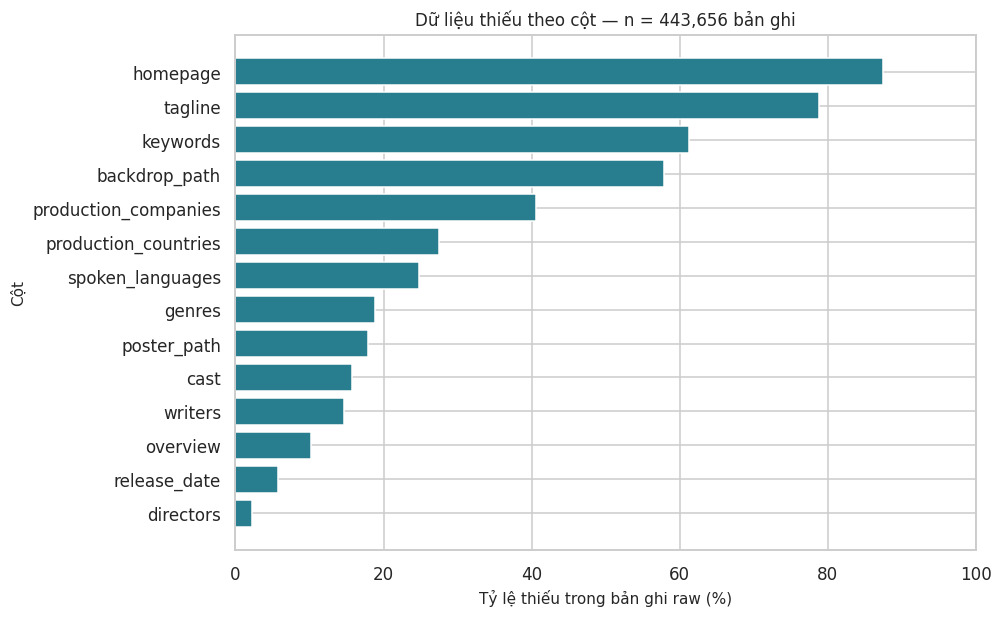

,release_date,genres,production_companies,production_countries,directors,writers,cast,số dòng,tỷ lệ raw (%)
0,False,False,False,False,False,False,False,198129,44.66
1,False,False,True,False,False,False,False,44472,10.02
2,False,False,True,True,False,False,False,30685,6.92
3,False,True,True,True,False,False,False,17951,4.05
4,False,False,False,False,False,True,False,15245,3.44
5,False,False,False,False,False,False,True,11308,2.55
6,True,True,True,True,False,False,False,10709,2.41
7,False,True,True,True,False,False,True,10318,2.33
8,False,False,False,True,False,False,False,8670,1.95
9,False,True,False,False,False,False,False,7686,1.73


Đồng thời thiếu ở cột,release_date,genres,production_companies,production_countries,directors,writers,cast
Thiếu ở cột,,,,,,,
release_date,25363,20069,23041,22768,792,3573,8911
genres,20069,83813,67844,59392,3470,19735,27839
production_companies,23041,67844,180269,106605,5111,34005,48860
production_countries,22768,59392,106605,121880,4600,23911,36616
directors,792,3470,5111,4600,10004,7486,3019
writers,3573,19735,34005,23911,7486,64952,22977
cast,8911,27839,48860,36616,3019,22977,69646


,số dòng,thiếu_release_date,thiếu_genres,thiếu_production_companies,thiếu_production_countries,thiếu_directors,thiếu_writers,thiếu_cast,budget_bằng_0,revenue_bằng_0,runtime_bằng_0,TMDB_không_lượt_chấm
status,,,,,,,,,,,,
Canceled,9,88.89,33.33,66.67,33.33,0.00,22.22,33.33,88.89,100.00,66.67,100.00
In Production,1043,37.20,16.30,28.76,28.19,0.96,7.19,6.62,92.71,99.90,68.46,100.00
Planned,161,70.19,14.91,26.71,27.95,1.86,5.59,7.45,91.93,100.00,84.47,100.00
Post Production,1676,57.10,12.77,27.33,24.76,0.42,4.95,4.53,92.30,100.00,64.32,99.88
Released,440762,5.42,18.92,40.72,27.48,2.27,14.70,15.76,93.16,96.22,13.50,38.77
Rumored,5,100.00,20.00,100.00,80.00,0.00,20.00,40.00,100.00,100.00,80.00,80.00


,số dòng,thiếu_release_date,thiếu_genres,thiếu_production_companies,thiếu_production_countries,thiếu_directors,thiếu_writers,thiếu_cast,budget_bằng_0,revenue_bằng_0,runtime_bằng_0,TMDB_không_lượt_chấm
original_language,,,,,,,,,,,,
Các ngôn ngữ còn lại,76007,2.70,11.90,34.17,17.05,0.72,9.74,10.61,95.69,97.39,17.86,40.20
de,21843,2.92,11.93,38.04,12.82,0.55,6.84,11.50,97.83,98.82,36.86,42.74
en,242967,8.07,23.41,45.58,36.70,3.55,18.72,19.13,90.76,95.42,9.10,41.87
es,21908,4.10,19.34,39.56,19.86,0.35,6.51,13.84,95.79,97.04,21.28,27.30
fr,24927,2.88,16.62,32.80,19.66,0.67,13.94,16.50,95.92,97.50,15.11,29.79
hi,6075,1.89,18.40,51.87,25.71,0.44,15.28,6.16,92.16,93.28,18.85,36.89
it,11978,3.34,13.81,30.18,20.95,0.56,6.86,7.83,96.72,97.65,22.82,27.84
ja,13285,0.78,10.52,22.58,3.22,1.81,10.56,7.30,98.07,96.50,3.20,25.98
pt,8287,3.21,13.50,40.71,13.60,0.64,11.81,14.70,96.11,98.66,21.30,42.51


,số dòng,thiếu_release_date,thiếu_genres,thiếu_production_companies,thiếu_production_countries,thiếu_directors,thiếu_writers,thiếu_cast,budget_bằng_0,revenue_bằng_0,runtime_bằng_0,TMDB_không_lượt_chấm
release_date,,,,,,,,,,,,
1870,19,0.0,15.79,94.74,57.89,0.00,100.00,100.00,94.74,100.00,15.79,57.89
1880,33,0.0,21.21,78.79,60.61,0.00,100.00,69.70,93.94,100.00,21.21,69.70
1890,1058,0.0,33.74,36.48,30.06,16.16,92.53,79.87,100.00,100.00,2.65,8.13
1900,2035,0.0,38.67,38.77,32.04,29.43,78.48,70.57,99.66,100.00,2.21,20.84
1910,4024,0.0,21.32,26.22,19.71,7.75,34.22,11.36,99.20,99.55,10.16,36.98
1920,5638,0.0,14.19,27.16,16.71,3.23,22.69,17.31,98.19,98.81,15.68,47.87
1930,12763,0.0,9.23,21.84,11.62,1.90,12.42,13.21,97.79,99.00,9.44,38.54
1940,11897,0.0,7.81,17.29,10.47,2.40,7.93,10.08,97.81,98.44,7.14,33.81
1950,15495,0.0,10.93,22.26,13.15,1.54,6.71,9.25,97.71,98.30,12.80,33.31


In [4]:
missing_table = pd.DataFrame({'NA khi đọc': movies.isna().sum(), 'chỉ khoảng trắng': space_only,
                              'số thiếu': missing.sum(), 'tỷ lệ thiếu (%)': 100 * missing.mean()})
missing_table = missing_table.sort_values('số thiếu', ascending=False)
display(missing_table.round(2))
fig, ax = plt.subplots(figsize=(9, 5.5), layout='constrained')
shown = missing_table.loc[missing_table['số thiếu'].gt(0)].sort_values('tỷ lệ thiếu (%)')
ax.barh(shown.index, shown['tỷ lệ thiếu (%)'], color='#287e8e')
ax.set(xlabel='Tỷ lệ thiếu trong bản ghi raw (%)', ylabel='Cột',
       title=f'Dữ liệu thiếu theo cột — n = {n:,} bản ghi', xlim=(0, 100))
plt.show()
important = ['release_date', 'genres', 'production_companies', 'production_countries',
             'directors', 'writers', 'cast']
patterns = missing[important].value_counts().head(10).rename('số dòng').reset_index()
patterns['tỷ lệ raw (%)'] = 100 * patterns['số dòng'] / n
display(patterns.round(2))
display((missing[important].astype('int64').T @ missing[important].astype('int64'))
        .rename_axis(index='Thiếu ở cột', columns='Đồng thời thiếu ở cột'))
# Cờ 0 là chẩn đoán riêng, không được trộn vào định nghĩa thiếu thật.
availability = missing[important].rename(columns=lambda c: 'thiếu_' + c).copy()
availability['budget_bằng_0'] = movies.budget.eq(0)
availability['revenue_bằng_0'] = movies.revenue.eq(0)
availability['runtime_bằng_0'] = movies.runtime.eq(0)
availability['TMDB_không_lượt_chấm'] = movies.vote_count.eq(0)

def missing_by_group(groups):
    result = availability.groupby(groups, observed=True, dropna=False).mean().mul(100)
    result.insert(0, 'số dòng', groups.value_counts(dropna=False))
    return result.round(2)

display(missing_by_group(movies.status))
top_languages = movies.original_language.value_counts().head(10).index
language_groups = movies.original_language.where(movies.original_language.isin(top_languages), 'Các ngôn ngữ còn lại')
display(missing_by_group(language_groups))
release_dates = pd.to_datetime(movies.release_date, format='%Y-%m-%d', errors='coerce')
decades = ((release_dates.dt.year // 10) * 10).astype('Int64').astype('string').fillna('Thiếu/không đọc được')
display(missing_by_group(decades))

**Hướng xử lý dự kiến:** giữ riêng cờ thiếu; chỉ lọc các trường cần thiết cho từng câu hỏi và báo cáo số mẫu.
Không bỏ mọi dòng chỉ vì thiếu ảnh, homepage hoặc tagline. Ngày thiếu không được tự suy từ tên phim.
Thể loại/đạo diễn thiếu có thể thành nhóm “chưa có thông tin” khi so sánh, nhưng cần kiểm tra thiên lệch nhóm.
Chưa xác minh vì sao từng ô bị thiếu; không gán nguyên nhân do ngân sách thấp hoặc phim ít nổi tiếng chỉ từ các bảng này.

## 4. Phân phối số, số 0 và cực trị

Bảng đầu giữ toàn bộ giá trị raw. Bảng thứ hai chỉ mô tả các giá trị **dương**, có báo cáo số mẫu;
đây là chẩn đoán sự lệch phân phối, chưa phải quyết định loại số 0.
Ngưỡng Tukey `Q1 − 1,5 × IQR`, `Q3 + 1,5 × IQR` chỉ gắn cờ để kiểm tra.
Giá trị ngoài ngưỡng chưa đủ để kết luận sai hay tự loại phim.

In [5]:
numeric_cols = ['budget', 'revenue', 'runtime', 'vote_average', 'vote_count',
                'averageRating', 'numVotes', 'popularity']
numeric_summary = movies[numeric_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T
numeric_summary['IQR'] = numeric_summary['75%'] - numeric_summary['25%']
numeric_summary['số 0'] = movies[numeric_cols].eq(0).sum()
numeric_summary['tỷ lệ 0 (%)'] = 100 * movies[numeric_cols].eq(0).mean()
numeric_summary['số âm'] = movies[numeric_cols].lt(0).sum()
with pd.option_context('display.max_columns', None):
    display(numeric_summary.round(3))

positive_cols = ['budget', 'revenue', 'runtime', 'vote_count', 'numVotes', 'popularity']
positive_summary = pd.DataFrame({col: movies.loc[movies[col].gt(0), col]
    .describe(percentiles=[.01, .25, .5, .75, .99]) for col in positive_cols}).T
display(positive_summary.round(3))

outliers = []
for col in numeric_cols:
    s = movies.loc[movies[col].gt(0), col] if col in positive_cols else movies[col].dropna()
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = s.lt(lo) | s.gt(hi)
    outliers.append([col, '> 0' if col in positive_cols else 'không thiếu', len(s),
                     lo, hi, flagged.sum(), 100 * flagged.mean()])
display(pd.DataFrame(outliers, columns=['cột', 'mẫu', 'n', 'ngưỡng dưới', 'ngưỡng trên',
                                        'số cờ IQR', 'tỷ lệ cờ (%)']).round(3))

numeric_checks = pd.Series({
    'budget hoặc revenue âm': int((movies.budget.lt(0) | movies.revenue.lt(0)).sum()),
    'budget và revenue cùng dương': int((movies.budget.gt(0) & movies.revenue.gt(0)).sum()),
    'TMDB ngoài [0, 10]': int((~movies.vote_average.between(0, 10)).sum()),
    'IMDb ngoài [1, 10]': int((~movies.averageRating.between(1, 10)).sum()),
    'TMDB điểm 0 nhưng có lượt chấm': int((movies.vote_average.eq(0) & movies.vote_count.gt(0)).sum()),
    'TMDB điểm dương nhưng 0 lượt chấm': int((movies.vote_average.gt(0) & movies.vote_count.eq(0)).sum()),
    'runtime bằng 0': int(movies.runtime.eq(0).sum()),
    'runtime trên 600 phút (cờ kiểm tra, không loại)': int(movies.runtime.gt(600).sum()),
})
display(numeric_checks.to_frame('Số bản ghi'))
for col in ['budget', 'revenue', 'runtime']:
    display(Markdown(f'**Ví dụ cực trị `{col}`: 3 dòng lớn nhất và 3 dòng dương nhỏ nhất.**'))
    positive = movies.loc[movies[col].gt(0)]
    example_index = positive.nlargest(3, col).index.union(positive.nsmallest(3, col).index)
    display(movies.loc[example_index, ['id', 'tconst', 'title', 'release_date', col]]
            .sort_values(col, ascending=False))

,count,mean,std,min,1%,25%,50%,75%,99%,max,IQR,số 0,tỷ lệ 0 (%),số âm
budget,443656.0,643344.339,7.379826e+06,0.0,0.0,0.0,0.000,0.000,1.564500e+07,8.880000e+08,0.000,413295,93.157,0
revenue,443656.0,1638287.557,2.601773e+07,0.0,0.0,0.0,0.000,0.000,2.414632e+07,2.923706e+09,0.000,427001,96.246,0
runtime,443656.0,66.247,6.423400e+01,0.0,0.0,15.0,80.000,96.000,1.800000e+02,1.440000e+04,81.000,61425,13.845,0
vote_average,443656.0,3.551,3.160000e+00,0.0,0.0,0.0,4.500,6.200,1.000000e+01,1.000000e+01,6.200,173876,39.192,0
vote_count,443656.0,47.946,5.077530e+02,0.0,0.0,0.0,1.000,5.000,8.450000e+02,3.449500e+04,5.000,173757,39.165,0
averageRating,443656.0,6.223,1.312000e+00,1.0,2.7,5.4,6.300,7.100,9.000000e+00,1.000000e+01,1.700,0,0.000,0
numVotes,443656.0,3264.497,3.492041e+04,5.0,7.0,24.0,74.000,356.000,5.755525e+04,3.261330e+06,332.000,0,0.000,0
popularity,443656.0,2.158,1.125100e+01,0.0,0.0,0.6,0.842,1.628,2.020600e+01,2.994357e+03,1.028,17761,4.003,0


,count,mean,std,min,1%,25%,50%,75%,99%,max
budget,30361.0,9.400994e+06,2.671189e+07,1.000,4.000,15000.0,500000.000,6.000000e+06,1.400000e+08,8.880000e+08
revenue,16655.0,4.364071e+07,1.272784e+08,1.000,10.000,343200.0,4296804.000,2.768394e+07,6.512521e+08,2.923706e+09
runtime,382231.0,7.689300e+01,6.301200e+01,1.000,2.000,51.0,86.000,9.900000e+01,1.820000e+02,1.440000e+04
vote_count,269899.0,7.881400e+01,6.491210e+02,1.000,1.000,2.0,4.000,1.200000e+01,1.563000e+03,3.449500e+04
numVotes,443656.0,3.264497e+03,3.492041e+04,5.000,7.000,24.0,74.000,3.560000e+02,5.755525e+04,3.261330e+06
popularity,425895.0,2.248000e+00,1.147500e+01,0.007,0.043,0.6,0.879,1.697000e+00,2.062000e+01,2.994357e+03


,cột,mẫu,n,ngưỡng dưới,ngưỡng trên,số cờ IQR,tỷ lệ cờ (%)
0,budget,> 0,30361,-8.962500e+06,1.497750e+07,4771,15.714
1,revenue,> 0,16655,-4.066792e+07,6.869506e+07,2419,14.524
2,runtime,> 0,382231,-2.100000e+01,1.710000e+02,5798,1.517
3,vote_average,không thiếu,443656,-9.300000e+00,1.550000e+01,0,0.000
4,vote_count,> 0,269899,-1.300000e+01,2.700000e+01,40271,14.921
5,averageRating,không thiếu,443656,2.850000e+00,9.650000e+00,5907,1.331
6,numVotes,> 0,443656,-4.740000e+02,8.540000e+02,71794,16.182
7,popularity,> 0,425895,-1.046000e+00,3.343000e+00,52031,12.217


,Số bản ghi
budget hoặc revenue âm,0
budget và revenue cùng dương,10425
"TMDB ngoài [0, 10]",0
"IMDb ngoài [1, 10]",0
TMDB điểm 0 nhưng có lượt chấm,457
TMDB điểm dương nhưng 0 lượt chấm,338
runtime bằng 0,61425
"runtime trên 600 phút (cờ kiểm tra, không loại)",233


**Ví dụ cực trị `budget`: 3 dòng lớn nhất và 3 dòng dương nhỏ nhất.**

,id,tconst,title,release_date,budget
400850,1057999,tt27219440,Enea,2023-09-21,888000000
270441,1399448,tt6161168,Red Dead Redemption 2 (Movie),2024-03-21,540000000
270442,1399448,tt6161168,Red Dead Redemption 2 (Movie),2024-03-21,540000000
11073,571055,tt9061402,Down,2019-02-01,1
12213,16664,tt0297721,All About Lily Chou-Chou,2001-10-06,1
14900,20034,tt1093369,Hush,2008-08-13,1


**Ví dụ cực trị `revenue`: 3 dòng lớn nhất và 3 dòng dương nhỏ nhất.**

,id,tconst,title,release_date,revenue
3,19995,tt0499549,Avatar,2009-12-15,2923706026
15,299534,tt4154796,Avengers: Endgame,2019-04-24,2800000000
281,76600,tt1630029,Avatar: The Way of Water,2022-12-14,2320250281
10094,14424,tt0497972,Sex and Death 101,2007-06-15,1
21385,500735,tt7823036,Finally Married,2018-01-25,1
21878,32834,tt0196106,MVP: Most Valuable Primate,2000-08-11,1


**Ví dụ cực trị `runtime`: 3 dòng lớn nhất và 3 dòng dương nhỏ nhất.**

,id,tconst,title,release_date,runtime
197760,251800,tt2659636,Modern Times Forever,2011-03-23,14400
334721,710874,tt11707418,Svalbard minutt for minutt,2020-01-31,13319
102153,272074,tt0242365,Cinématon,1978-12-20,12480
7162,160,tt0000012,The Arrival of a Train at La Ciotat,1897-10-10,1
9018,774,tt0000010,Workers Leaving the Lumière Factory,1895-03-22,1
10846,82120,tt0000014,The Sprinkler Sprinkled,1895-06-10,1


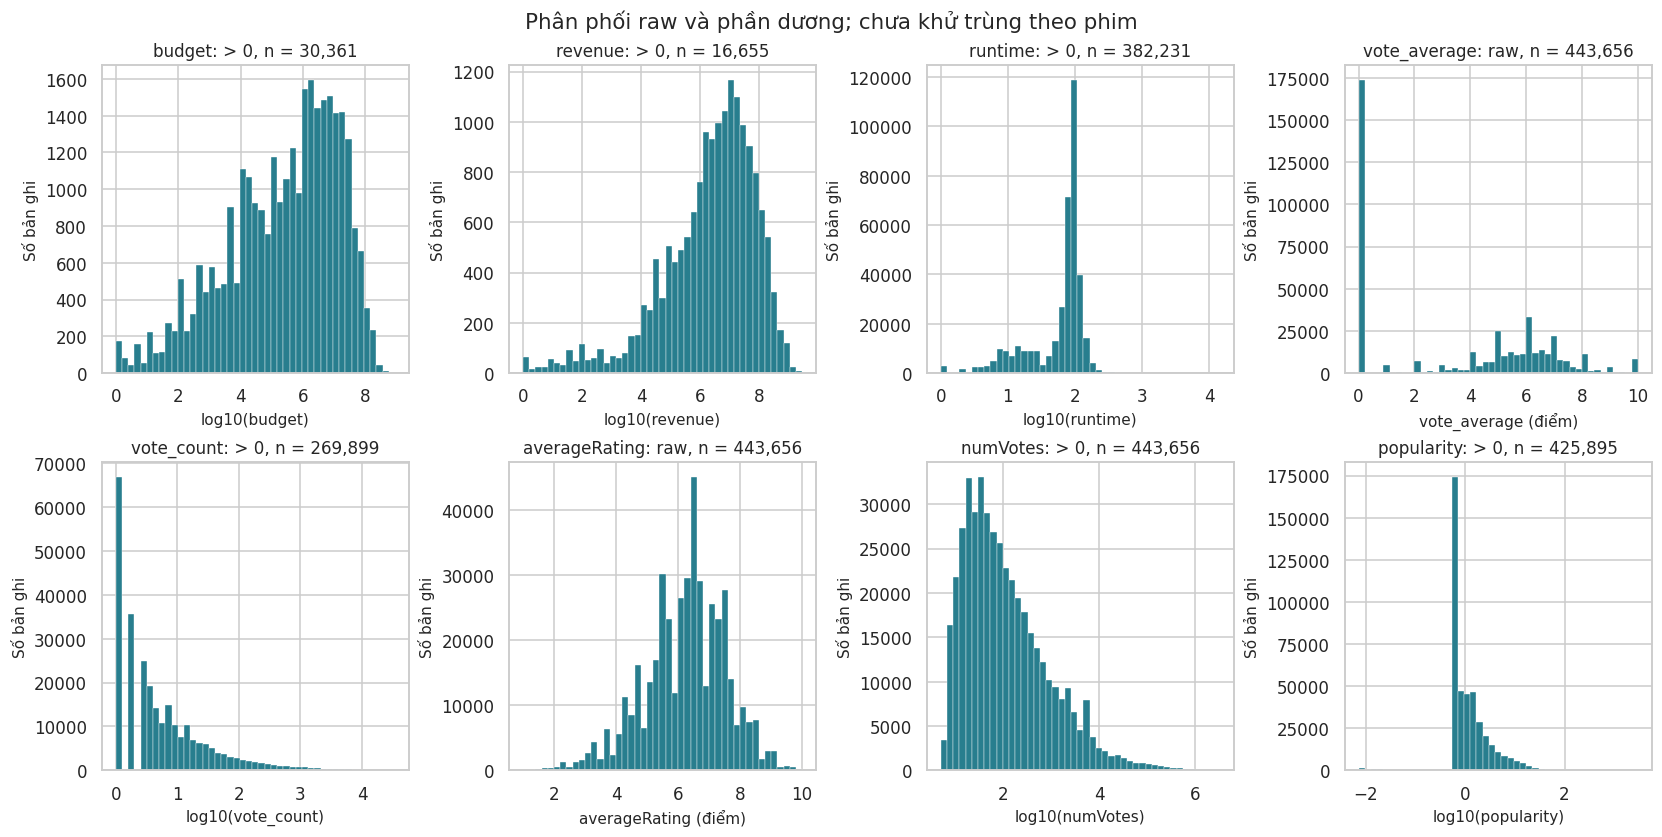

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5), layout='constrained')
for ax, col in zip(axes.flat, numeric_cols):
    s = movies[col].dropna()
    if col in positive_cols:
        s = s[s.gt(0)]
        plotted = np.log10(s)
        label = f'log10({col})'
        scope = '> 0'
    else:
        plotted = s
        label = f'{col} (điểm)'
        scope = 'raw'
    ax.hist(plotted, bins=45, color='#287e8e', edgecolor='white', linewidth=.25)
    ax.set(title=f'{col}: {scope}, n = {len(s):,}', xlabel=label, ylabel='Số bản ghi')
fig.suptitle('Phân phối raw và phần dương; chưa khử trùng theo phim', fontsize=14)
plt.show()

**Cách đọc:** dùng log10 cho các biến dương lệch phải để vẫn thấy toàn bộ khoảng giá trị.
Các số 0 không hiện trong histogram log, nhưng đã được đếm ở bảng phía trên.
`runtime` có đơn vị phút; tài chính chưa có metadata xác nhận đơn vị từng dòng.
Ngưỡng 600 phút chỉ giúp tìm ví dụ cần đối chiếu, không khẳng định tác phẩm dài là lỗi.
Không winsorize, điền thiếu, điều chỉnh lạm phát hoặc suy ra lợi nhuận trong notebook này.

## 5. Biến phân loại, đa nhãn và ngày

Đếm nhóm hiếm ở mức **tối đa 5 bản ghi** chỉ để chẩn đoán, chưa gom vào “khác” cho phân tích.
Kiểm tra nhãn sau `strip()` và `casefold()` để tìm các cách viết có thể trùng nghĩa.
Không tự gộp nhãn nếu chưa xác minh ý nghĩa.

In [7]:
category_audit = []
for col in ['original_language', 'status', 'adult']:
    counts = movies.loc[~missing[col], col].value_counts()
    category_audit.append([col, len(counts), int(counts.le(5).sum()), int(counts[counts.le(5)].sum()),
                           int(missing[col].sum())])
    display(Markdown(f'**`{col}`: nhóm phổ biến (tối đa 15).**'))
    display(pd.DataFrame({'số bản ghi': counts.head(15), 'tỷ lệ raw (%)': counts.head(15) * 100 / n}).round(2))
display(pd.DataFrame(category_audit, columns=['cột', 'số nhãn', 'nhãn có ≤5 dòng',
                                             'dòng thuộc nhãn hiếm', 'số thiếu']))
label_checks = []
for col in ['original_language', 'status']:
    values = movies.loc[~missing[col], col]
    pairs = pd.DataFrame({'raw': values, 'normalized': values.str.strip().str.casefold()}).drop_duplicates()
    collisions = pairs.groupby('normalized').raw.nunique()
    label_checks.append([col, int(values.ne(values.str.strip()).sum()), int(collisions.gt(1).sum())])
    rare = values.value_counts()
    display(rare[rare.le(5)].head(20).to_frame(f'{col}: ví dụ nhãn hiếm'))
display(pd.DataFrame(label_checks, columns=['cột', 'dòng có khoảng trắng thừa', 'nhãn chuẩn hóa có nhiều cách viết']))
display(pd.Series({'original_language không phải 2 chữ cái thường':
    int((~movies.original_language.str.fullmatch(r'[a-z]{2}', na=False)).sum())}))

**`original_language`: nhóm phổ biến (tối đa 15).**

,số bản ghi,tỷ lệ raw (%)
original_language,,
en,242967,54.76
fr,24927,5.62
es,21908,4.94
de,21843,4.92
ja,13285,2.99
it,11978,2.70
ru,9472,2.13
pt,8287,1.87
zh,6907,1.56


**`status`: nhóm phổ biến (tối đa 15).**

,số bản ghi,tỷ lệ raw (%)
status,,
Released,440762,99.35
Post Production,1676,0.38
In Production,1043,0.24
Planned,161,0.04
Canceled,9,0.00
Rumored,5,0.00


**`adult`: nhóm phổ biến (tối đa 15).**

,số bản ghi,tỷ lệ raw (%)
adult,,
False,431223,97.2
True,12433,2.8


,cột,số nhãn,nhãn có ≤5 dòng,dòng thuộc nhãn hiếm,số thiếu
0,original_language,158,38,79,0
1,status,6,1,5,0
2,adult,2,0,0,0


,original_language: ví dụ nhãn hiếm
original_language,
fy,5
cr,4
ce,4
sm,4
tt,4
gn,4
lg,3
ny,3
ti,3


,status: ví dụ nhãn hiếm
status,
Rumored,5


,cột,dòng có khoảng trắng thừa,nhãn chuẩn hóa có nhiều cách viết
0,original_language,0,0
1,status,0,0


original_language không phải 2 chữ cái thường    0
dtype: int64

In [8]:
display(movies.loc[~missing.genres, 'genres'].head(10).to_frame('Ví dụ chuỗi genres raw'))
# Chỉ áp dụng parser này cho genres: dữ liệu thực dùng tên thể loại phân cách bằng dấu phẩy.
genre_lists = movies.genres.fillna('').str.split(',').map(lambda parts: [p.strip() for p in parts if p.strip()])
genre_count = genre_lists.map(len)
genre_duplicate_tokens = genre_lists.map(lambda parts: len(parts) != len(set(parts)))
genre_brackets = movies.genres.fillna('').str.contains(r'[\[\]{}]', regex=True)
display(pd.Series({'dòng thiếu genres': int(missing.genres.sum()),
    'dòng có nhiều thể loại': int(genre_count.gt(1).sum()),
    'dòng lặp nhãn trong cùng genres': int(genre_duplicate_tokens.sum()),
    'dòng chứa dấu ngoặc cần parser khác': int(genre_brackets.sum()),
    'số thể loại tối đa trên một dòng': int(genre_count.max())}))
genre_tokens = genre_lists.map(lambda parts: sorted(set(parts))).explode().dropna()
genre_counts = genre_tokens.value_counts()
display(pd.DataFrame({'số bản ghi chứa thể loại': genre_counts,
                      'tỷ lệ trong raw (%)': 100 * genre_counts / n}).round(2))
display(genre_count.value_counts().sort_index().to_frame('Số bản ghi theo số nhãn genres'))

invalid_dates = ~missing.release_date & release_dates.isna()
non_iso = ~missing.release_date & ~movies.release_date.str.fullmatch(r'\d{4}-\d{2}-\d{2}', na=False)
date_audit = pd.Series({'thiếu release_date': int(missing.release_date.sum()),
    'có giá trị nhưng không parse được': int(invalid_dates.sum()),
    'chuỗi không đúng YYYY-MM-DD': int(non_iso.sum()),
    'ngày sớm nhất': str(release_dates.min().date()),
    'ngày muộn nhất': str(release_dates.max().date()),
    'sau ngày nhóm tải 05/11/2026': int(release_dates.gt(DOWNLOAD_DATE).sum()),
    'Released nhưng ngày sau ngày tải': int((release_dates.gt(DOWNLOAD_DATE) & movies.status.eq('Released')).sum())})
display(date_audit.to_frame('Kết quả'))
display(movies.loc[invalid_dates | non_iso | release_dates.gt(DOWNLOAD_DATE),
                   ['id', 'tconst', 'title', 'release_date', 'status']].head(15))

,Ví dụ chuỗi genres raw
0,"Action, Science Fiction, Adventure"
1,"Adventure, Drama, Science Fiction"
2,"Drama, Action, Crime, Thriller"
3,"Action, Adventure, Fantasy, Science Fiction"
4,"Science Fiction, Action, Adventure"
5,"Action, Adventure, Comedy"
6,"Adventure, Action, Science Fiction"
7,Drama
8,"Action, Science Fiction, Adventure"
9,"Thriller, Crime"


dòng thiếu genres                       83813
dòng có nhiều thể loại                 171236
dòng lặp nhãn trong cùng genres            95
dòng chứa dấu ngoặc cần parser khác         0
số thể loại tối đa trên một dòng           11
dtype: int64

,số bản ghi chứa thể loại,tỷ lệ trong raw (%)
genres,,
Drama,140009,31.56
Comedy,92583,20.87
Documentary,59518,13.42
Romance,35904,8.09
Thriller,33768,7.61
Action,32986,7.44
Horror,31615,7.13
Animation,26322,5.93
Crime,25105,5.66


,Số bản ghi theo số nhãn genres
genres,
0,83813
1,188607
2,108518
3,47958
4,11443
5,2570
6,628
7,95
8,18


,Kết quả
thiếu release_date,25363
có giá trị nhưng không parse được,0
chuỗi không đúng YYYY-MM-DD,0
ngày sớm nhất,1874-12-09
ngày muộn nhất,2029-10-13
sau ngày nhóm tải 05/11/2026,3
Released nhưng ngày sau ngày tải,2


,id,tconst,title,release_date,status
272007,1225835,tt8270746,শূন্যতা,2027-04-21,Released
286448,1355413,tt5835938,Pela Adhi Akshar,2027-03-24,In Production
287509,1227249,tt10333734,Indiana Jones: Return of Elsa Schneider,2029-10-13,Released


Mỗi phim có thể thuộc nhiều thể loại nên tổng tỷ lệ thể loại có thể vượt 100%.
Bảng trên đếm số **bản ghi raw chứa nhãn**, chưa là số phim duy nhất.
Không cộng doanh thu sau khi `explode()` nếu chưa quy định cách phân bổ.
Không tái dùng cách tách `genres` cho tên công ty/người khi chưa kiểm tra vì tên có thể chứa dấu phẩy.
Ngày tương lai có thể là lịch dự kiến; ngày hợp lệ về cú pháp không bảo đảm đúng về nội dung.
Các dòng `Released` nhưng ngày sau ngày tải cần được đối chiếu riêng với nguồn.

## 6. Mối liên hệ sơ bộ — đã chọn mẫu A

**Quyết định ngày 15/11/2026:** người dùng chọn **A**. Giữ raw để kiểm tra chất lượng,
chỉ dùng dòng có cả `id` và `tconst` xuất hiện đúng một lần cho quan hệ sơ bộ.
Các phương án đã cân nhắc:

| Chọn | Cách làm | Ưu điểm | Nhược điểm |
| --- | --- | --- | --- |
| A (đề xuất) | Raw cho kiểm tra chất lượng; quan hệ trên dòng có cả `id` và `tconst` xuất hiện đúng một lần | Không đếm lặp, chưa đoán cách gộp | Loại cả phim chỉ khác danh sách diễn viên; có thể lệch mẫu |
| B | Gộp cùng `id`, kiểm tra xung đột trước khi tính quan hệ | Giữ được nhiều phim | Cần thêm quy tắc chọn giá trị và xử lý `tconst` dùng chung |
| C | Tính trên toàn bộ bản ghi raw | Ít biến đổi dữ liệu | Phim có nhiều dòng mang trọng số lớn hơn; không suy ra quan hệ ở mức phim |

**Quyết định 2 — A:** quan hệ tài chính chỉ dùng `budget > 0` và `revenue > 0`.
Ưu điểm: tránh diễn giải các số 0 chưa rõ nghĩa. Nhược điểm: mẫu nhỏ và có thể thiên lệch do độ đầy đủ dữ liệu.

**Quyết định 3 — A:** so sánh điểm trên toàn bộ mẫu hợp lệ có lượt chấm,
rồi kiểm tra thêm các ngưỡng **10, 100, 1.000 lượt ở cả hai nền tảng**.
Ưu điểm: thấy độ nhạy với ngưỡng. Nhược điểm: các mẫu lồng nhau và khác nhau về thành phần phim.
Các lựa chọn chỉ áp dụng cho phần khám phá này, giữ nguyên CSV gốc.

In [9]:
analysis_base = movies.loc[unique_keys].copy()
sample_flow = pd.DataFrame([
    ['Raw', n, 0],
    ['Cả id và tconst xuất hiện đúng một lần', len(analysis_base), n - len(analysis_base)],
], columns=['bước', 'số dòng còn lại', 'số dòng loại ở bước này'])
sample_flow['tỷ lệ giữ so với raw (%)'] = 100 * sample_flow['số dòng còn lại'] / n
display(sample_flow.round(2))
assert analysis_base.id.is_unique and analysis_base.tconst.is_unique
comparison = pd.DataFrame({label: {
    'số dòng': len(frame),
    'budget > 0 (%)': 100 * frame.budget.gt(0).mean(),
    'revenue > 0 (%)': 100 * frame.revenue.gt(0).mean(),
    'thiếu genres (%)': 100 * frame.genres.isna().mean(),
    'ngôn ngữ gốc en (%)': 100 * frame.original_language.eq('en').mean(),
    'status Released (%)': 100 * frame.status.eq('Released').mean(),
} for label, frame in [('Raw', movies), ('Mẫu A', analysis_base)]})
display(comparison.round(2))

,bước,số dòng còn lại,số dòng loại ở bước này,tỷ lệ giữ so với raw (%)
0,Raw,443656,0,100.00
1,Cả id và tconst xuất hiện đúng một lần,425189,18467,95.84


,Raw,Mẫu A
số dòng,443656.00,425189.00
budget > 0 (%),6.84,6.72
revenue > 0 (%),3.75,3.79
thiếu genres (%),18.89,17.46
ngôn ngữ gốc en (%),54.76,53.58
status Released (%),99.35,99.34


### 6.1. Ngân sách và doanh thu được ghi nhận

Từ mẫu A, chỉ giữ các dòng có **cả `budget > 0` và `revenue > 0`** theo quyết định 2A.
Giữ toàn bộ cực trị dương và các trạng thái trong mẫu này, chưa áp dụng ngưỡng ngân sách, năm hay outlier khác.
So sánh Pearson trên giá trị gốc, Pearson sau log10 và Spearman theo thứ hạng để mô tả các mặt khác nhau của quan hệ.
Log10 chỉ dùng để hiển thị và tính thêm thống kê, không sửa các cột gốc.

,bước,số dòng còn lại,số dòng loại ở bước này,tỷ lệ so với mẫu A (%),tỷ lệ so với raw (%)
0,Mẫu A,425189,0,100.00,95.84
1,budget > 0 và revenue > 0,10165,415024,2.39,2.29


,budget – revenue
n,10165.0000
Pearson giá trị gốc,0.7433
Pearson log10,0.8150
Spearman,0.7704


,count,mean,std,min,25%,50%,75%,99%,max
budget,10165.0,23290185.10,3.779754e+07,1.0,2000000.0,9400000.0,27000000.0,2.000000e+08,4.600000e+08
revenue,10165.0,65246451.38,1.548824e+08,1.0,1689501.0,12348905.0,57000000.0,7.921283e+08,2.923706e+09


,Mẫu A,Tài chính dương
số dòng,425189.00,10165.0
ngôn ngữ gốc en (%),53.58,76.0
status Released (%),99.34,100.0
năm phát hành trung vị,2005.00,2006.0


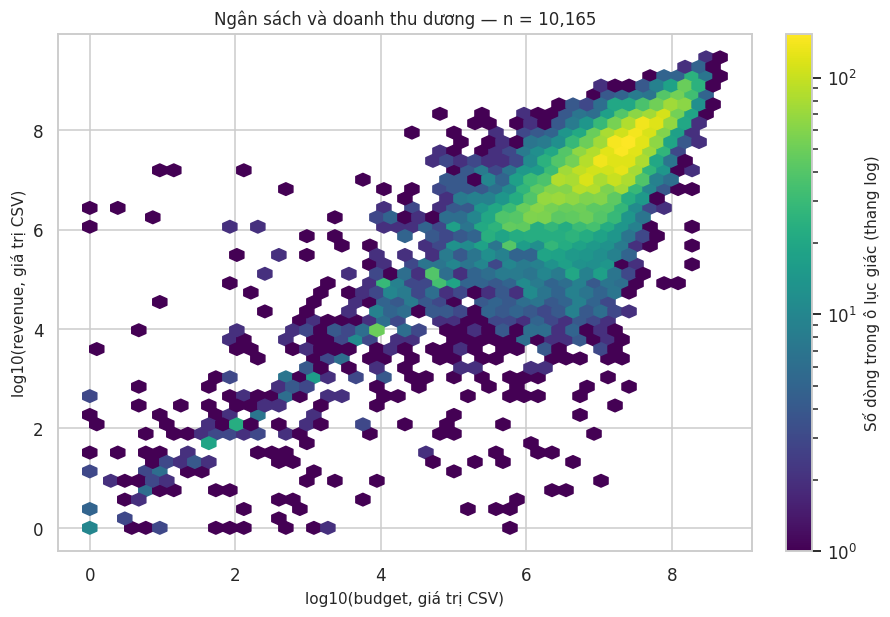

Mẫu tài chính có **10,165 dòng** (**2.39%** mẫu A; **2.29%** raw). Pearson gốc = **0.743**, Pearson log10 = **0.815**, Spearman = **0.770**. Các hệ số mô tả quan hệ trong mẫu đã lọc; chưa chứng minh ngân sách gây ra doanh thu.

In [10]:
finance = analysis_base.loc[analysis_base.budget.gt(0) & analysis_base.revenue.gt(0)].copy()
finance_flow = pd.DataFrame([
    ['Mẫu A', len(analysis_base), 0],
    ['budget > 0 và revenue > 0', len(finance), len(analysis_base) - len(finance)],
], columns=['bước', 'số dòng còn lại', 'số dòng loại ở bước này'])
finance_flow['tỷ lệ so với mẫu A (%)'] = 100 * finance_flow['số dòng còn lại'] / len(analysis_base)
finance_flow['tỷ lệ so với raw (%)'] = 100 * finance_flow['số dòng còn lại'] / n
display(finance_flow.round(2))
finance_log = np.log10(finance[['budget', 'revenue']])
finance_metrics = pd.Series({
    'n': len(finance),
    'Pearson giá trị gốc': finance.budget.corr(finance.revenue, method='pearson'),
    'Pearson log10': finance_log.budget.corr(finance_log.revenue, method='pearson'),
    'Spearman': finance.budget.corr(finance.revenue, method='spearman'),
}, name='budget – revenue')
display(finance_metrics.to_frame().round(4))
display(finance[['budget', 'revenue']].describe(percentiles=[.25, .5, .75, .99]).T.round(2))
finance_profile = pd.DataFrame({label: {
    'số dòng': len(frame),
    'ngôn ngữ gốc en (%)': 100 * frame.original_language.eq('en').mean(),
    'status Released (%)': 100 * frame.status.eq('Released').mean(),
    'năm phát hành trung vị': release_dates.loc[frame.index].dt.year.median(),
} for label, frame in [('Mẫu A', analysis_base), ('Tài chính dương', finance)]})
display(finance_profile.round(2))

fig, ax = plt.subplots(figsize=(8, 5.5), layout='constrained')
hb = ax.hexbin(finance_log.budget, finance_log.revenue, gridsize=45,
               mincnt=1, bins='log', cmap='viridis')
fig.colorbar(hb, ax=ax, label='Số dòng trong ô lục giác (thang log)')
ax.set(title=f'Ngân sách và doanh thu dương — n = {len(finance):,}',
       xlabel='log10(budget, giá trị CSV)', ylabel='log10(revenue, giá trị CSV)')
plt.show()
display(Markdown(f'Mẫu tài chính có **{len(finance):,} dòng** '
    f'(**{len(finance)/len(analysis_base):.2%}** mẫu A; **{len(finance)/n:.2%}** raw). '
    f'Pearson gốc = **{finance_metrics["Pearson giá trị gốc"]:.3f}**, '
    f'Pearson log10 = **{finance_metrics["Pearson log10"]:.3f}**, '
    f'Spearman = **{finance_metrics["Spearman"]:.3f}**. '
    'Các hệ số mô tả quan hệ trong mẫu đã lọc; chưa chứng minh ngân sách gây ra doanh thu.'))

Biểu đồ dùng **toàn bộ mẫu tài chính**, gộp mật độ vào các ô lục giác để giảm chồng điểm, không lấy mẫu ngẫu nhiên.
Đối chiếu bảng thành phần với mẫu A trước khi khái quát kết quả. Mẫu có tài chính dương có thể khác các dòng bị loại.
Chưa xác minh đơn vị tiền tệ từng dòng, chưa điều chỉnh thời gian/lạm phát và chưa kiểm soát thể loại.
Hệ số trên log10 mô tả quan hệ trên thang biến đổi, không so trực tiếp độ lớn với hệ số trên giá trị gốc.

### 6.2. Điểm TMDB–IMDb và lượt chấm

Từ mẫu A, mẫu so sánh cặp gồm **TMDB trong [0, 10], IMDb trong [1, 10], `vote_count > 0` và `numVotes > 0`**.
Điểm TMDB bằng 0 nhưng có lượt vẫn nằm trong miền giá trị được kiểm tra; số trường hợp này được báo cáo riêng,
chưa tự sửa hoặc loại thêm. Đặt `Δ = vote_average − averageRating` (điểm).

Các ngưỡng 10/100/1.000 áp dụng đồng thời cho `vote_count` và `numVotes`, bắt đầu từ cùng mẫu cặp hợp lệ.
Đây là các mẫu **lồng nhau**, không phải bốn nhóm phim độc lập.
So sánh Pearson, Spearman, chênh lệch trung bình/trung vị và chênh lệch tuyệt đối trung bình.
Chênh lệch dương nghĩa là điểm TMDB cao hơn IMDb trong mẫu đó.

,bước,số dòng còn lại,số dòng loại ở bước này
0,Mẫu A,425189,0
1,Cặp điểm hợp lệ và có lượt ở cả hai nền tảng,267113,158076


,n,loại thêm từ mẫu cặp hợp lệ,giữ so với mẫu cặp (%),Pearson,Spearman,Δ trung bình,Δ trung vị,|Δ| trung bình,TMDB điểm 0 có lượt
ngưỡng lượt ở cả hai,,,,,,,,,
1,267113,0,100.0000,0.4582,0.5147,-0.2821,-0.200,1.1293,446
10,77681,189432,29.0817,0.7856,0.7820,0.0061,-0.100,0.5272,0
100,18056,249057,6.7597,0.8555,0.8650,0.1156,-0.013,0.3692,0
1000,3930,263183,1.4713,0.9006,0.9012,0.0659,-0.026,0.2784,0


,bước,số dòng còn lại,số dòng loại ở bước này
0,Mẫu A,425189,0
1,"IMDb điểm [1, 10] và numVotes > 0",425189,0


IMDb theo lượt: n = 425,189; Spearman = -0.1399


,n,diem_trung_binh,diem_trung_vi,do_lech_chuan
Nhóm lượt chấm IMDb (không chồng lấn),,,,
1–9,19735,6.762,6.8,1.330
10–99,225714,6.363,6.4,1.274
100–999,125933,5.872,6.0,1.275
1.000–9.999,41194,6.140,6.4,1.223
10.000–99.999,9910,6.502,6.6,1.050
≥100.000,2703,6.993,7.0,0.821


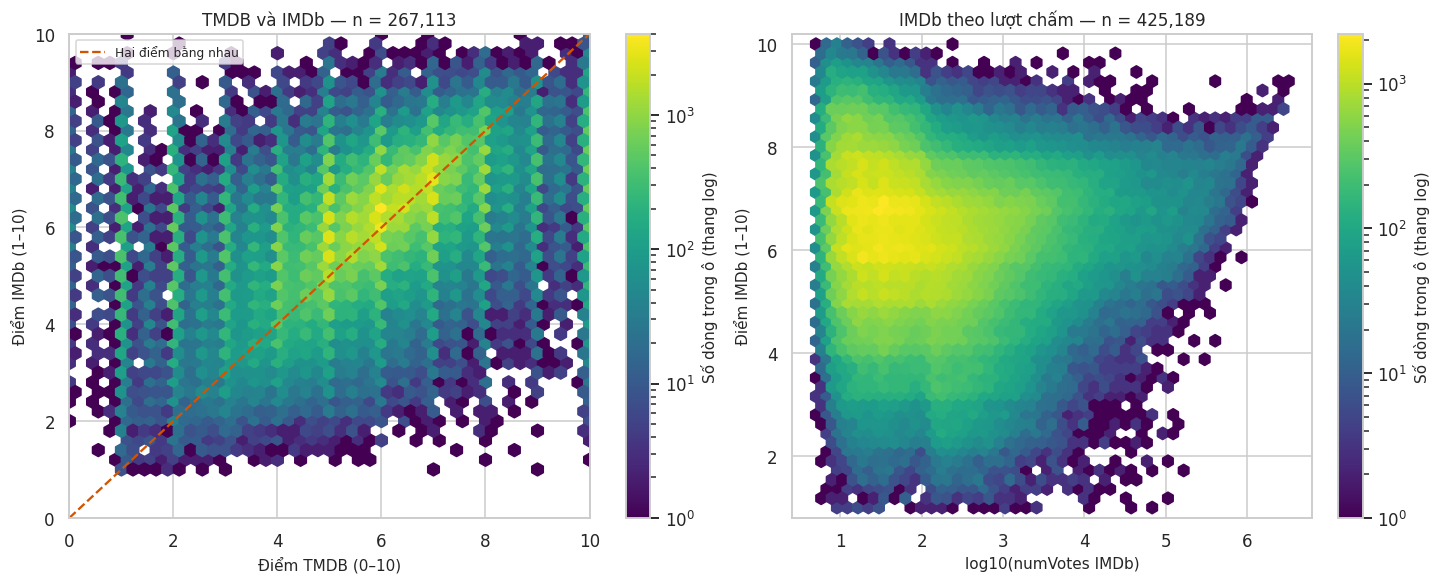

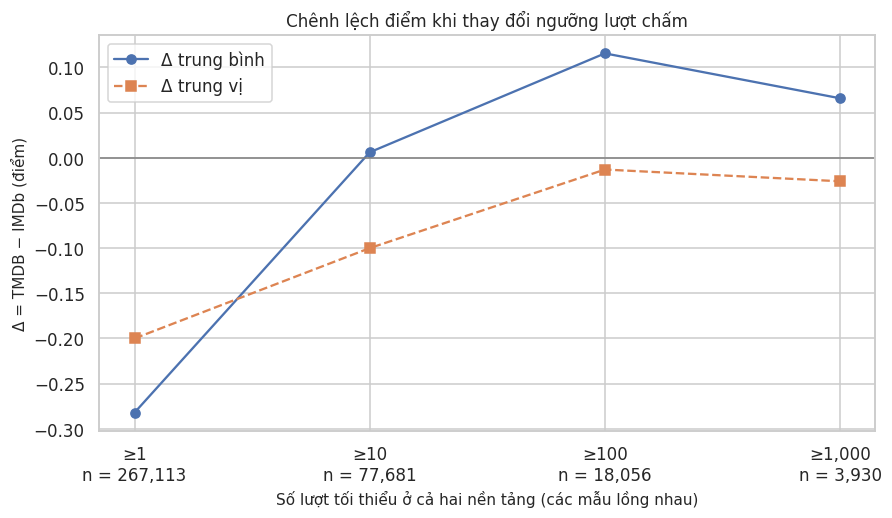

Mẫu cặp hợp lệ gồm **267,113 dòng** (62.82% mẫu A). Chênh lệch trung bình Δ = **-0.282** điểm và Spearman = **0.515**. Ở ngưỡng ≥1.000 lượt cả hai, còn **3,930 dòng**, Δ trung bình = **0.066** điểm và Spearman = **0.901**.

In [11]:
rating_mask = (analysis_base.vote_average.between(0, 10)
               & analysis_base.averageRating.between(1, 10)
               & analysis_base.vote_count.gt(0) & analysis_base.numVotes.gt(0))
paired_ratings = analysis_base.loc[rating_mask].copy()
paired_ratings['rating_gap'] = paired_ratings.vote_average - paired_ratings.averageRating
rating_rows = []
threshold_samples = {}
for threshold in [1, 10, 100, 1000]:
    subset = paired_ratings.loc[paired_ratings.vote_count.ge(threshold)
                                 & paired_ratings.numVotes.ge(threshold)]
    threshold_samples[threshold] = subset
    rating_rows.append({
        'ngưỡng lượt ở cả hai': threshold,
        'n': len(subset),
        'loại thêm từ mẫu cặp hợp lệ': len(paired_ratings) - len(subset),
        'giữ so với mẫu cặp (%)': 100 * len(subset) / len(paired_ratings),
        'Pearson': subset.vote_average.corr(subset.averageRating),
        'Spearman': subset.vote_average.corr(subset.averageRating, method='spearman'),
        'Δ trung bình': subset.rating_gap.mean(),
        'Δ trung vị': subset.rating_gap.median(),
        '|Δ| trung bình': subset.rating_gap.abs().mean(),
        'TMDB điểm 0 có lượt': int(subset.vote_average.eq(0).sum()),
    })
rating_sensitivity = pd.DataFrame(rating_rows).set_index('ngưỡng lượt ở cả hai')
rating_flow = pd.DataFrame([
    ['Mẫu A', len(analysis_base), 0],
    ['Cặp điểm hợp lệ và có lượt ở cả hai nền tảng', len(paired_ratings), len(analysis_base) - len(paired_ratings)],
], columns=['bước', 'số dòng còn lại', 'số dòng loại ở bước này'])
display(rating_flow)
with pd.option_context('display.max_columns', None):
    display(rating_sensitivity.round(4))

# Quan hệ IMDb với lượt chấm dùng mẫu IMDb hợp lệ riêng, không đòi phim có lượt TMDB.
imdb_ratings = analysis_base.loc[analysis_base.averageRating.between(1, 10)
                                 & analysis_base.numVotes.gt(0)].copy()
display(pd.DataFrame([
    ['Mẫu A', len(analysis_base), 0],
    ['IMDb điểm [1, 10] và numVotes > 0', len(imdb_ratings), len(analysis_base) - len(imdb_ratings)],
], columns=['bước', 'số dòng còn lại', 'số dòng loại ở bước này']))
imdb_votes_rho = imdb_ratings.numVotes.corr(imdb_ratings.averageRating, method='spearman')
print(f'IMDb theo lượt: n = {len(imdb_ratings):,}; Spearman = {imdb_votes_rho:.4f}')
vote_groups = pd.cut(imdb_ratings.numVotes, bins=[1, 10, 100, 1000, 10000, 100000, np.inf],
                     right=False, labels=['1–9', '10–99', '100–999', '1.000–9.999',
                                          '10.000–99.999', '≥100.000'])
imdb_by_votes = imdb_ratings.groupby(vote_groups, observed=True).agg(
    n=('id', 'size'), diem_trung_binh=('averageRating', 'mean'),
    diem_trung_vi=('averageRating', 'median'), do_lech_chuan=('averageRating', 'std'))
imdb_by_votes.index.name = 'Nhóm lượt chấm IMDb (không chồng lấn)'
display(imdb_by_votes.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), layout='constrained')
hb = axes[0].hexbin(paired_ratings.vote_average, paired_ratings.averageRating,
                    gridsize=45, mincnt=1, bins='log', cmap='viridis', extent=(0, 10, 0, 10))
axes[0].plot([0, 10], [0, 10], '--', color='#d35400', linewidth=1.5, label='Hai điểm bằng nhau')
axes[0].set(title=f'TMDB và IMDb — n = {len(paired_ratings):,}',
            xlabel='Điểm TMDB (0–10)', ylabel='Điểm IMDb (1–10)', xlim=(0, 10), ylim=(0, 10))
axes[0].legend(loc='upper left', fontsize=8)
fig.colorbar(hb, ax=axes[0], label='Số dòng trong ô (thang log)')
hb = axes[1].hexbin(np.log10(imdb_ratings.numVotes), imdb_ratings.averageRating,
                    gridsize=45, mincnt=1, bins='log', cmap='viridis')
axes[1].set(title=f'IMDb theo lượt chấm — n = {len(imdb_ratings):,}',
            xlabel='log10(numVotes IMDb)', ylabel='Điểm IMDb (1–10)', ylim=(0.8, 10.2))
fig.colorbar(hb, ax=axes[1], label='Số dòng trong ô (thang log)')
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.6), layout='constrained')
positions = np.arange(len(rating_sensitivity))
ax.plot(positions, rating_sensitivity['Δ trung bình'], 'o-', label='Δ trung bình')
ax.plot(positions, rating_sensitivity['Δ trung vị'], 's--', label='Δ trung vị')
ax.axhline(0, color='grey', linewidth=1)
ax.set_xticks(positions, [f'≥{threshold:,}\nn = {int(row["n"]):,}'
                        for threshold, row in rating_sensitivity.iterrows()])
ax.set(title='Chênh lệch điểm khi thay đổi ngưỡng lượt chấm',
       xlabel='Số lượt tối thiểu ở cả hai nền tảng (các mẫu lồng nhau)',
       ylabel='Δ = TMDB − IMDb (điểm)')
ax.legend()
plt.show()
display(Markdown(f'Mẫu cặp hợp lệ gồm **{len(paired_ratings):,} dòng** '
    f'({len(paired_ratings)/len(analysis_base):.2%} mẫu A). '
    f'Chênh lệch trung bình Δ = **{rating_sensitivity.loc[1, "Δ trung bình"]:.3f}** điểm '
    f'và Spearman = **{rating_sensitivity.loc[1, "Spearman"]:.3f}**. '
    f'Ở ngưỡng ≥1.000 lượt cả hai, còn **{int(rating_sensitivity.loc[1000, "n"]):,} dòng**, '
    f'Δ trung bình = **{rating_sensitivity.loc[1000, "Δ trung bình"]:.3f}** điểm '
    f'và Spearman = **{rating_sensitivity.loc[1000, "Spearman"]:.3f}**.'))

Các biểu đồ dùng toàn bộ mẫu được nêu, không lấy ngẫu nhiên một phần phim.
Tương quan đo mức đồng biến, không đo hai nền tảng cho điểm bằng nhau; xem thêm `Δ` và `|Δ|`.
Thay đổi khi nâng ngưỡng có thể phản ánh thành phần phim và khán giả khác nhau,
không chứng minh nhiều lượt chấm làm điểm tăng/giảm hoặc nền tảng nào đánh giá “đúng” hơn.
Điểm hai nguồn có thể được chụp ở thời điểm khác nhau; dữ liệu không chứa lịch sử lượt chấm.
Đây là khám phá mẫu hình, chưa có kiểm định, khoảng tin cậy hay kiểm soát yếu tố gây nhiễu.

## 7. Tóm tắt khám phá và hướng tiền xử lý

Các số liệu dưới đây được tính từ kết quả chạy; nhóm dùng để tự viết nhận xét của mình.
Phạm vi là các bản ghi raw và những mẫu con đã nêu, chưa chốt bốn câu hỏi phân tích của nhóm.

In [12]:
finance_positive = movies.budget.gt(0) & movies.revenue.gt(0)
notes = [
    f'CSV có {n:,} bản ghi, {movies.shape[1]} cột, {int(movies.duplicated().sum()):,} dòng trùng toàn bộ; '
    f'nhưng {int(movies.id.duplicated().sum()):,} dòng dư theo id và {int(movies.tconst.duplicated().sum()):,} dòng dư theo tconst.',
    f'budget bằng 0 ở {int(movies.budget.eq(0).sum()):,} dòng ({movies.budget.eq(0).mean():.2%}); '
    f'revenue bằng 0 ở {int(movies.revenue.eq(0).sum()):,} dòng ({movies.revenue.eq(0).mean():.2%}). '
    f'Cả hai dương ở {int(finance_positive.sum()):,} dòng ({finance_positive.mean():.2%}).',
    f'release_date thiếu ở {int(missing.release_date.sum()):,} dòng ({missing.release_date.mean():.2%}); '
    f'genres thiếu ở {int(missing.genres.sum()):,} dòng ({missing.genres.mean():.2%}). '
    f'runtime bằng 0 ở {int(movies.runtime.eq(0).sum()):,} dòng ({movies.runtime.eq(0).mean():.2%}) '
    f'và cực đại {int(movies.runtime.max()):,} phút. Có {int(space_only.sum()):,} ô chỉ chứa khoảng trắng.',
    f'Trên {len(finance):,} dòng có hai mã duy nhất và tài chính cùng dương, '
    f'Spearman budget–revenue = {finance_metrics["Spearman"]:.3f}, '
    f'Pearson gốc = {finance_metrics["Pearson giá trị gốc"]:.3f} '
    f'và Pearson log10 = {finance_metrics["Pearson log10"]:.3f}. '
    f'Mẫu này chỉ chiếm {len(finance)/n:.2%} raw, hạn chế phạm vi khái quát.',
    f'Mẫu cặp điểm có {len(paired_ratings):,} dòng; Δ trung bình TMDB−IMDb '
    f'= {rating_sensitivity.loc[1, "Δ trung bình"]:.3f} điểm. '
    f'Khi cả hai đạt ≥1.000 lượt, còn {int(rating_sensitivity.loc[1000, "n"]):,} dòng, '
    f'Δ trung bình = {rating_sensitivity.loc[1000, "Δ trung bình"]:.3f} điểm. '
    'Phải nêu ngưỡng và số mẫu khi so sánh hai nền tảng.',
]
display(Markdown('\n\n'.join(f'{i}. {note}' for i, note in enumerate(notes, 1))))

1. CSV có 443,656 bản ghi, 29 cột, 0 dòng trùng toàn bộ; nhưng 13,894 dòng dư theo id và 16,995 dòng dư theo tconst.

2. budget bằng 0 ở 413,295 dòng (93.16%); revenue bằng 0 ở 427,001 dòng (96.25%). Cả hai dương ở 10,425 dòng (2.35%).

3. release_date thiếu ở 25,363 dòng (5.72%); genres thiếu ở 83,813 dòng (18.89%). runtime bằng 0 ở 61,425 dòng (13.85%) và cực đại 14,400 phút. Có 67 ô chỉ chứa khoảng trắng.

4. Trên 10,165 dòng có hai mã duy nhất và tài chính cùng dương, Spearman budget–revenue = 0.770, Pearson gốc = 0.743 và Pearson log10 = 0.815. Mẫu này chỉ chiếm 2.29% raw, hạn chế phạm vi khái quát.

5. Mẫu cặp điểm có 267,113 dòng; Δ trung bình TMDB−IMDb = -0.282 điểm. Khi cả hai đạt ≥1.000 lượt, còn 3,930 dòng, Δ trung bình = 0.066 điểm. Phải nêu ngưỡng và số mẫu khi so sánh hai nền tảng.

**Vấn đề chất lượng cần lưu ý:** mã lặp và mã IMDb liên kết nhiều TMDB; số 0 tài chính/thời lượng;
điểm TMDB bằng 0 nhưng có lượt và điểm dương nhưng không có lượt; 95 dòng lặp nhãn thể loại;
2 dòng `Released` có ngày sau ngày tải. Nguyên nhân từng trường hợp chưa được xác minh.

**Đã áp dụng cho khám phá:** mẫu hai mã duy nhất cho quan hệ; tài chính dương cho quan hệ tài chính;
lọc cặp điểm theo miền giá trị và lượt chấm, so sánh độ nhạy ngưỡng 1/10/100/1.000.
Các bảng chất lượng vẫn dùng raw, chưa ghi dữ liệu processed.

**Tiền xử lý dự kiến cho phân tích sau:** nhóm thống nhất đơn vị tác phẩm và cách xử lý mã lặp;
giữ cờ thiếu/tài chính 0/thời lượng 0, lọc theo từng câu hỏi; parse ngày và thể loại trên bản phân tích;
không tự điền toàn bộ cột, không loại tất cả outlier hoặc mọi dòng có NA.
Nếu dùng tài chính, xác minh tiền tệ, phạm vi doanh thu và cách so sánh qua thời gian.

**Mẫu hình để nhóm chọn câu hỏi:** quan hệ tài chính thay đổi ra sao trong các nhóm ngân sách,
thời kỳ và thể loại; chênh lệch điểm TMDB–IMDb có còn tương tự trong các nhóm lượt chấm/thể loại;
phân bố thể loại/thời lượng thay đổi thế nào khi giữ cùng phạm vi tác phẩm qua thời gian.
Đây chưa là danh sách câu hỏi đã chốt hoặc kết luận nhân quả.

**Các điểm nhóm cần thống nhất khi chốt câu hỏi:** phim điện ảnh hay gồm phim ngắn/truyền hình;
có tiếp tục dùng mẫu hai mã duy nhất hay điều tra cách gộp để giữ thêm phim;
ngưỡng lượt chấm chính cho từng câu hỏi; cách xử lý tài chính 0, cực trị và khác biệt thời gian.
Đây là các quyết định cho bước đặt câu hỏi/phân tích tiếp theo, không cản trở bàn giao khám phá raw.

In [13]:
# Xác nhận file nguồn không đổi trong lần chạy và các bảng kiểm tra khớp số dòng.
assert file_sha256(RAW_PATH) == raw_sha256, 'CSV đã thay đổi trong lúc chạy.'
assert wrong_width_records == 0, 'Có bản ghi sai số trường, cần kiểm tra trước khi diễn giải.'
assert csv_records - empty_records == n
assert missing.shape == movies.shape
assert missing_table['số thiếu'].between(0, n).all()
assert analysis_base.id.is_unique and analysis_base.tconst.is_unique
assert finance[['budget', 'revenue']].gt(0).all().all()
assert finance.index.isin(analysis_base.index).all()
assert paired_ratings.index.isin(analysis_base.index).all()
assert rating_sensitivity['n'].is_monotonic_decreasing
assert rating_sensitivity.loc[1, 'n'] == len(paired_ratings)
assert imdb_by_votes['n'].sum() == len(imdb_ratings)
assert rating_sensitivity[['Pearson', 'Spearman']].abs().le(1).all().all()
print('Đã kiểm tra raw và các mẫu quan hệ; SHA-256 nguồn không thay đổi.')

Đã kiểm tra raw và các mẫu quan hệ; SHA-256 nguồn không thay đổi.
